# Bài thực hành Buổi 1 - Bài 2 Trang 28
## Dữ liệu Bank Marketing

In [1]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style="whitegrid")


Ngô Thành Khôi - 6451071038


### Câu 1: Tự động đọc dữ liệu Bank Marketing

In [2]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Tìm file bank-full.csv hoặc bank.csv trong thư mục hiện tại
from pathlib import Path

candidates = [ROOT for ROOT in [Path("bank-full.csv"), Path("bank.csv")] if ROOT.exists()]
if not candidates:
    raise FileNotFoundError("Không tìm thấy bank-full.csv hoặc bank.csv")

bank_file = candidates[0]
# Tự động thử dấu phân cách ';' rồi ','
df_bank = pd.read_csv(bank_file, sep=";")
if df_bank.shape[1] == 1:
    df_bank = pd.read_csv(bank_file, sep=",")

print("File sử dụng:", bank_file)
display(df_bank.head())
print("\nThông tin:")
df_bank.info()
print("\nThống kê mô tả:")
display(df_bank.describe(include="all"))

selected = ["job", "marital", "education", "default", "loan", "duration", "cons.price.idx", "y"]
for col in selected:
    if col in df_bank.columns:
        print(f"{col}: rỗng={df_bank[col].isna().sum()}, unknown={(df_bank[col].astype(str).str.lower() == 'unknown').sum()}")


Ngô Thành Khôi - 6451071038
File sử dụng: bank-full.csv


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Thông tin:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB

Thống kê mô tả:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
count,45211.000000,45211,45211,45211,45211,45211.000000,45211,45211,45211,45211.000000,45211,45211.000000,45211.000000,45211.000000,45211.000000,45211,45211
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2
top,NaN,blue-collar,married,secondary,no,NaN,yes,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no
freq,NaN,9732,27214,23202,44396,NaN,25130,37967,29285,NaN,13766,NaN,NaN,NaN,NaN,36959,39922
mean,40.936210,NaN,NaN,NaN,NaN,1362.272058,NaN,NaN,NaN,15.806419,NaN,258.163080,2.763841,40.197828,0.580323,NaN,NaN
std,10.618762,NaN,NaN,NaN,NaN,3044.765829,NaN,NaN,NaN,8.322476,NaN,257.527812,3.098021,100.128746,2.303441,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-8019.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,33.000000,NaN,NaN,NaN,NaN,72.000000,NaN,NaN,NaN,8.000000,NaN,103.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,448.000000,NaN,NaN,NaN,16.000000,NaN,180.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,48.000000,NaN,NaN,NaN,NaN,1428.000000,NaN,NaN,NaN,21.000000,NaN,319.000000,3.000000,-1.000000,0.000000,NaN,NaN


job: rỗng=0, unknown=288
marital: rỗng=0, unknown=0
education: rỗng=0, unknown=1857
default: rỗng=0, unknown=0
loan: rỗng=0, unknown=0
duration: rỗng=0, unknown=0
y: rỗng=0, unknown=0


### Câu 2: Trực quan hóa quan hệ với khả năng đăng ký

Ngô Thành Khôi - 6451071038


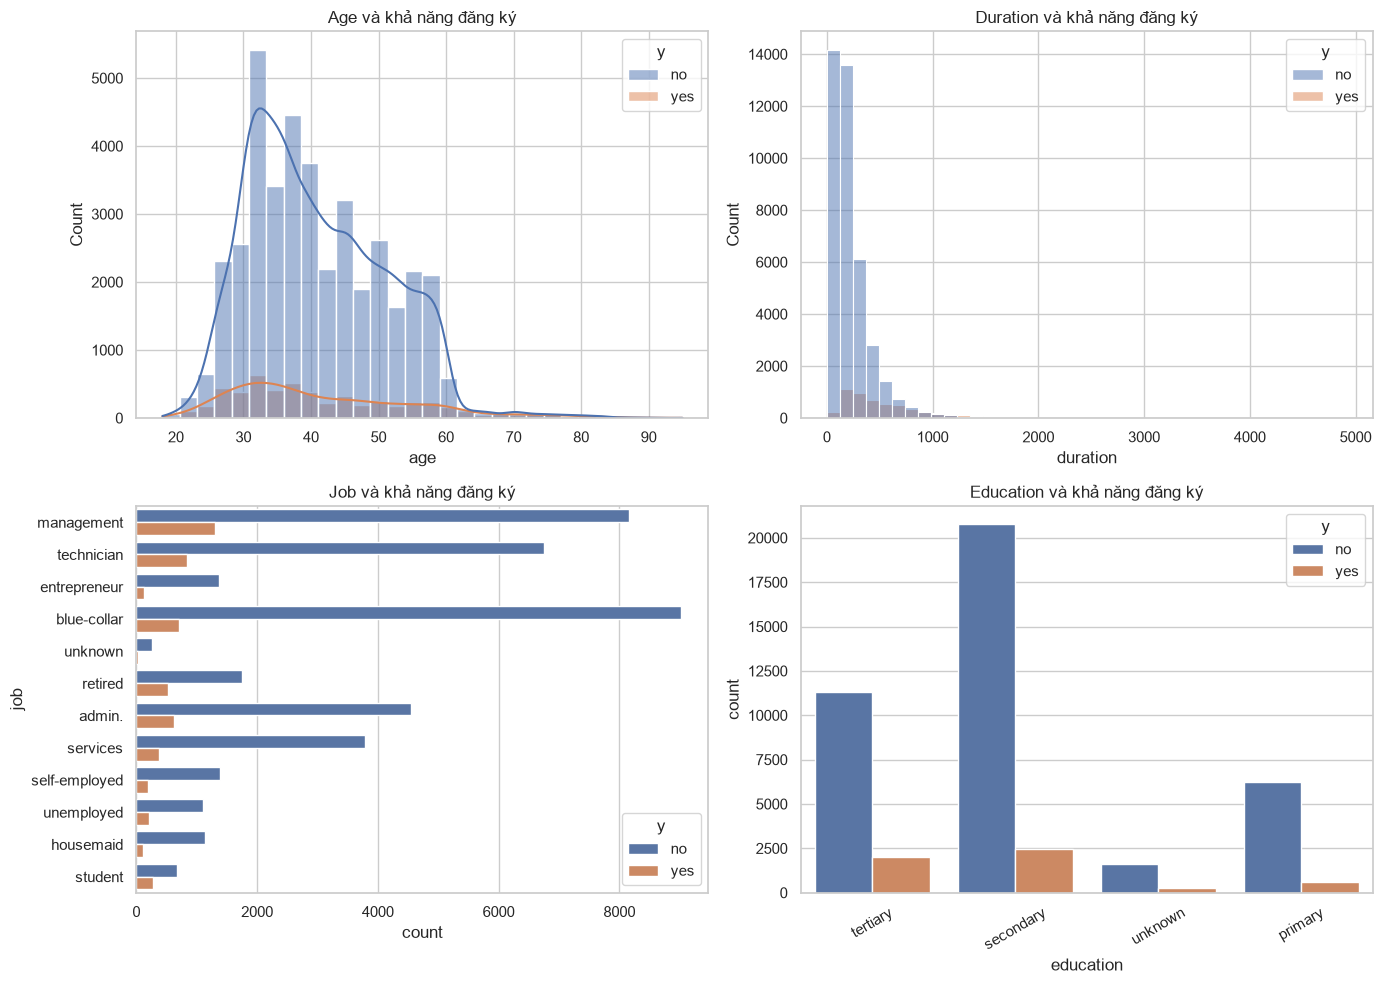

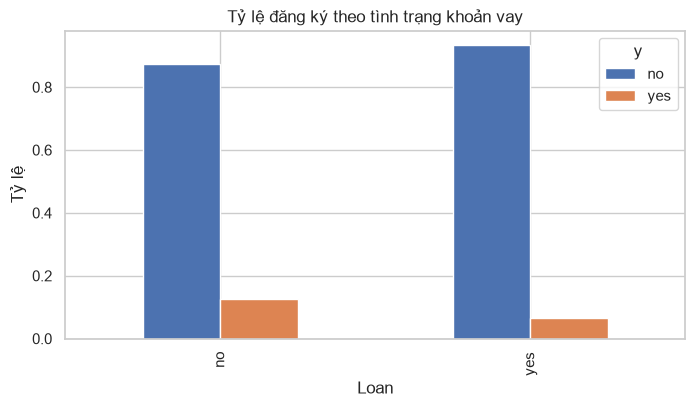

In [3]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Vẽ trực quan cho age, duration, job, education, loan
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(data=df_bank, x="age", hue="y", kde=True, bins=30, ax=axes[0, 0])
axes[0, 0].set_title("Age và khả năng đăng ký")
sns.histplot(data=df_bank, x="duration", hue="y", bins=40, ax=axes[0, 1])
axes[0, 1].set_title("Duration và khả năng đăng ký")
sns.countplot(data=df_bank, y="job", hue="y", ax=axes[1, 0])
axes[1, 0].set_title("Job và khả năng đăng ký")
sns.countplot(data=df_bank, x="education", hue="y", ax=axes[1, 1])
axes[1, 1].tick_params(axis="x", rotation=30)
axes[1, 1].set_title("Education và khả năng đăng ký")
plt.tight_layout()
plt.show()

pd.crosstab(df_bank["loan"], df_bank["y"], normalize="index").plot(kind="bar", figsize=(8, 4))
plt.title("Tỷ lệ đăng ký theo tình trạng khoản vay")
plt.xlabel("Loan")
plt.ylabel("Tỷ lệ")
plt.show()


**Nhận xét:** Duration có liên quan mạnh tới kết quả liên hệ; age ảnh hưởng không tuyến tính. Retired/student và nhóm có học vấn cao có xu hướng đăng ký tốt hơn, khách có khoản vay 'yes' thường có tỷ lệ đăng ký thấp hơn.

### Câu 3: Tiền xử lý unknown, mã hóa phân loại và rời rạc hóa

In [4]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Thay unknown bằng giá trị phổ biến nhất ở từng cột phân loại
categorical_cols = df_bank.select_dtypes(include=["object"]).columns
for col in categorical_cols:
    df_bank[col] = df_bank[col].replace("unknown", np.nan)
    mode = df_bank[col].mode()
    if len(mode):
        df_bank[col] = df_bank[col].fillna(mode.iloc[0])

# Mã hóa các thuộc tính phân loại được yêu cầu
encode_cols = ["job", "marital", "education", "default", "housing", "loan", "y"]
for col in encode_cols:
    if col in df_bank.columns:
        df_bank[col] = pd.Categorical(df_bank[col]).codes

# Rời rạc hóa age thành 8 nhóm
df_bank["age"] = pd.cut(
    df_bank["age"], bins=[-np.inf, 30, 35, 40, 45, 50, 55, 60, np.inf], labels=False
)

# Rời rạc hóa duration thành 6 nhóm
df_bank["duration"] = pd.cut(
    df_bank["duration"], bins=[-np.inf, 60, 120, 180, 300, 600, np.inf], labels=False
)

print("Kiểu dữ liệu sau tiền xử lý:")
display(df_bank.dtypes)
print("Phân bố age:")
display(df_bank["age"].value_counts().sort_index())
print("Phân bố duration:")
display(df_bank["duration"].value_counts().sort_index())
display(df_bank.head())


Ngô Thành Khôi - 6451071038
Kiểu dữ liệu sau tiền xử lý:


C:\Users\Thanh Khoi\AppData\Local\Temp\ipykernel_1820\2132614588.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_bank.select_dtypes(include=["object"]).columns


age          int64
job           int8
marital       int8
education     int8
default       int8
balance      int64
housing       int8
loan          int8
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y             int8
dtype: object

Phân bố age:


age
0    7030
1    9877
2    7810
3    6046
4    5193
5    4355
6    3712
7    1188
Name: count, dtype: int64

Phân bố duration:


duration
0     4766
1     9278
2     8616
3    10277
4     8484
5     3790
Name: count, dtype: int64

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,6,4,1,2,0,2143,1,0,cellular,5,may,3,1,-1,0,failure,0
1,3,9,2,1,0,29,1,0,cellular,5,may,2,1,-1,0,failure,0
2,1,2,1,1,0,2,1,1,cellular,5,may,1,1,-1,0,failure,0
3,4,1,1,1,0,1506,1,0,cellular,5,may,1,1,-1,0,failure,0
4,1,1,2,1,0,1,0,0,cellular,5,may,3,1,-1,0,failure,0
